# Reading and visualising a mesh with meshio++ (Octave/MATLAB)

Octave/MATLAB counterpart of [`../r/01_read_and_visualize.ipynb`](../r/01_read_and_visualize.ipynb),
[`../python/01_read_and_visualize.ipynb`](../python/01_read_and_visualize.ipynb) and
[`../cpp/01_read_and_visualize.ipynb`](../cpp/01_read_and_visualize.ipynb): the same bracket geometry, read
and inspected through the **Octave/MATLAB binding** (`bindings/octave/meshioplusplus`), which binds the
installed C API exactly as the R package does. Every R function `mio_foo(...)` is `mio.foo(...)` here.

Like the C++ and R notebooks, this reads [`example.vtu`](./example.vtu) rather than `example/example.msh`
directly -- the identical file the C++ and R notebooks use; see [`README.md`](./README.md).

**On rendering:** there is no PyVista in Octave/MATLAB. The R notebooks draw through the SVG writer, which the
flat C API reaches only with its fixed default styling (`doc/formats/svg.md` documents that data-driven
colouring is a **flat-ABI gap**). These notebooks draw through meshio++'s own **software rasterizer** instead
(`mio.render`), which the C API reaches with **every** option, so a render can be coloured by a quality metric
or a field, with a colorbar. [`render.m`](./render.m) shows a frame with `image()`, and the octave kernel
captures each figure as an inline PNG. The R notebooks' charts are kept as well
([`mio_bar_chart.m`](./mio_bar_chart.m)/[`mio_histogram.m`](./mio_histogram.m): plain `barh`/`hist`).

As in R, **every accessor copies** (see [`doc/octave.md`](../../doc/octave.md)), and connectivity indices are
1-based throughout. Arrays put one entity per row: `mio.points(m)` is `num_points x 3`.

In [1]:
warning('off', 'Octave:shadowed-function');
addpath(fullfile(pwd, '..', '..', 'bindings', 'octave', 'meshioplusplus', 'inst'));
mio_notebook

meshio++ 18.2.0 (Octave/MATLAB binding)


## Read the mesh

In [2]:
mesh = mio.read('example.vtu');

fprintf('points      : %d\n', mio.num_points(mesh));
fprintf('cell blocks : %d\n', mio.num_cell_blocks(mesh));
fprintf('cell totals :\n');
for i = 1:mio.num_cell_blocks(mesh)
    info = mio.cell_block_info(mesh, i);
    fprintf('    %-10s %8d\n', mio.cell_block_type(mesh, i), info.num_cells);
end

s = mio.stats(mesh);
fprintf('bounding box: (%.3f, %.3f, %.3f) -> (%.3f, %.3f, %.3f)\n', s.bbox_min, s.bbox_max);

points      : 52282


cell blocks : 2


cell totals :


    triangle      58394
    tetra        235014


bounding box: (-3.505, -3.185, 0.000) -> (0.000, 0.625, 0.382)


## Visualise the full part

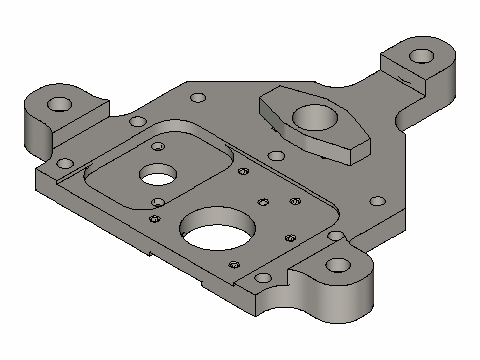

In [3]:
render(mesh)

## Clip to reveal the interior

`mio.crop_plane` keeps the cells on one side of a plane (`(p - point) . normal >= 0`) and returns a real,
smaller mesh — the same building block the CLI's `crop --plane` uses. Cropping to the half of the part
with `x` below its midpoint exposes the tetrahedra that were previously hidden inside the solid.

clipped points: 17741 (from 52282)


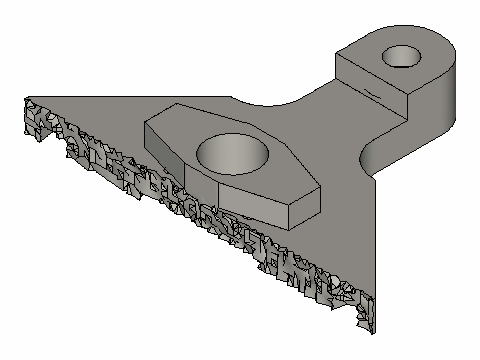

In [4]:
mid_x = 0.5 * (s.bbox_min(1) + s.bbox_max(1));
clipped = mio.crop_plane(mesh, [mid_x 0 0], [-1 0 0], 'mode', 'any');
fprintf('clipped points: %d (from %d)\n', mio.num_points(clipped), mio.num_points(mesh));
render(clipped)

## Element quality, as a colour and as a chart

`mio.attach_quality` writes each metric back as `cell_data`. We crop to a legible corner first (the full
skin is tens of thousands of facets), then colour the corner by `quality:scaled_jacobian` -- the C++
notebook's colour-by-quality render, which the rasterizer reaches through `'color_by'` -- and show the
same distribution as a histogram, as the R notebook does.

corner: 772 points, 2842 tetrahedra


quality:scaled_jacobian min=0.0823 mean=0.4321 max=0.9842


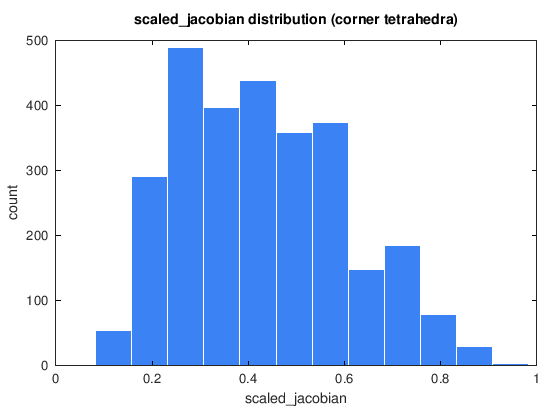

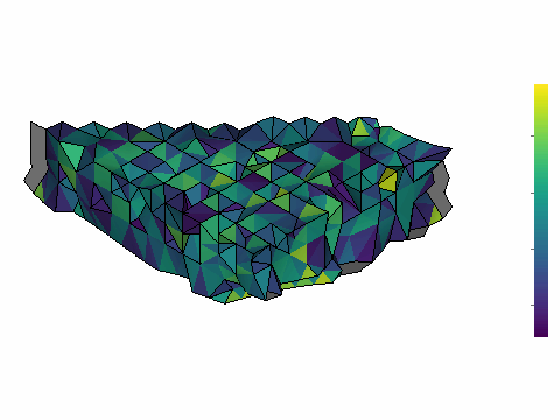

In [5]:
corner_hi = s.bbox_min + (s.bbox_max - s.bbox_min) * 0.4;
corner = mio.crop_bbox(mesh, s.bbox_min, corner_hi);
annotated = mio.attach_quality(corner);
tet_block = mio.num_cell_blocks(annotated);
info = mio.cell_block_info(annotated, tet_block);
fprintf('corner: %d points, %d tetrahedra\n', mio.num_points(annotated), info.num_cells);

sj = mio.cell_data(annotated, 'quality:scaled_jacobian', tet_block);
sj = sj(isfinite(sj));
fprintf('quality:scaled_jacobian min=%.4f mean=%.4f max=%.4f\n', min(sj), mean(sj), max(sj));
render(annotated, 'color_by', 'quality:scaled_jacobian', 'cmap', 'viridis', 'colorbar', true)
mio_histogram(sj, 'scaled_jacobian distribution (corner tetrahedra)', 'scaled_jacobian')

## A field, as a colour and as a chart

The corner's height (`z`) is a signed quantity relative to the bracket's base. `mio.points` returns one point
per row, so `z` is the third column. Attached as point data it drives the render's colour map; the histogram
is the R notebook's view of the same values.

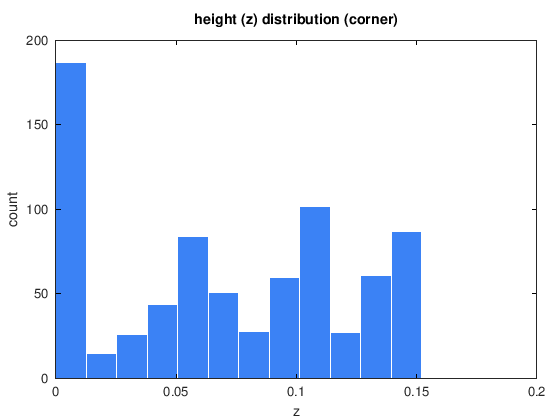

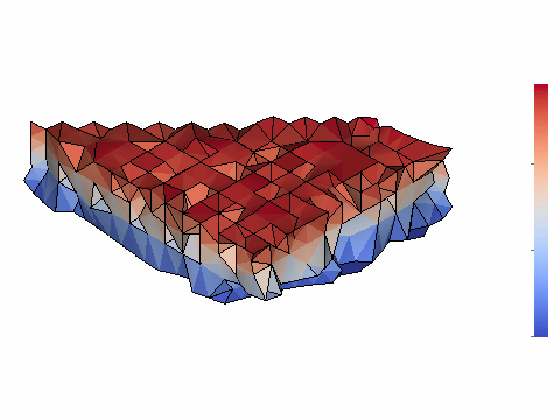

In [6]:
p = mio.points(corner);   % num_points x 3
z = p(:, 3);
mio.add_point_data(corner, 'z', z);
render(corner, 'color_by', 'z', 'cmap', 'coolwarm', 'colorbar', true)
mio_histogram(z, 'height (z) distribution (corner)', 'z')

The same `--color-by NAME --colorbar` options are available on the command line, and from the SVG and TikZ
writers through the **full C++ API** -- the flat C API's SVG writer takes no styling, which is why these
notebooks use the rasterizer.

That's the round trip: **meshio++'s C API reads the mesh** through the Octave/MATLAB binding, computes quality
metrics on it, and its own rasterizer renders it — no Python, no external rendering library. See
[`02_convert_and_inspect.ipynb`](./02_convert_and_inspect.ipynb) for converting the same mesh between
formats, and [`03_mesh_operations.ipynb`](./03_mesh_operations.ipynb) for the rest of the operations
layer.